# Estudio 06 · Fase 1b · Consistencia del clima: lo descargado frente a ERA5 fijo (2017-2025)

`openmeteo.py` descargó 2017-2025 sin fijar `models`, así que Open-Meteo usó su «Best match», que según su
documentación combina IFS HRES, ERA5 y ERA5-Land (https://open-meteo.com/en/docs/historical-weather-api). El
modelo elegido puede no ser el mismo en todos los años. Antes de usar el clima 2000-2016, este notebook compara,
semana por semana y en los mismos distritos, lo ya descargado con ERA5 fijado explícitamente.

- **Entrada:** `data/bronze/meteo/cache_meteo/` (actual) y `data/bronze/meteo/cache_meteo_era5_2017_2025/`
  (celda A del notebook 02 del pipeline, la corre el equipo). Solo lee; no descarga ni escribe en `data/`.
- **Agregación:** la misma del notebook 03 del pipeline (`aggregate_to_weekly`).
- **Salida:** `docs/metricas/fase1b_consistencia.json` y `docs/figuras/fase1b/`.
- **También:** cuántos distritos comparten celda de ERA5 (0,25°) y si eso deja distritos con clima idéntico.
- **Qué se mira:** la diferencia ERA5 − actual por variable (media, MAE, máximo, correlación, semanas iguales) y
  **por año**. Un salto entre años indica que el «Best match» cambió de modelo dentro de 2017-2025.
- La decisión (descargar 2000-2016 con «Best match», con ERA5 fijo o 2000-2025 con un solo modelo, que movería
  gold y la paridad de la V2) la toma Rosa. Este notebook no la toma.


In [1]:
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

from denguekay.config.paths import CACHE_METEO, CACHE_METEO_ERA5_2017_2025, RESEARCH

STUDY = RESEARCH / "06_model_improvement"
sys.path.insert(0, str(STUDY / "code"))
import phase1b_climate as cl

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
METRICS = STUDY / "docs" / "metricas" / "fase1b_consistencia.json"
FIGURES = STUDY / "docs" / "figuras" / "fase1b"
if not any(CACHE_METEO_ERA5_2017_2025.glob("distrito_*.parquet")):
    raise RuntimeError("Falta el caché ERA5: corran la celda A del notebook 02 del pipeline.")


## 1 · Cobertura: las dos descargas deben tener las mismas semanas


In [2]:
res = cl.run_comparison(CACHE_METEO_ERA5_2017_2025, CACHE_METEO)
res["cobertura"]


65 archivos


65 archivos


{'semanas_actual': 30485,
 'semanas_fijo': 30485,
 'solo_actual': 0,
 'solo_fijo': 0}

## 2 · Diferencia ERA5 − actual por variable, 2017-2025


In [3]:
res["por_variable"].round(4)


,variable,filas,nulos,media_actual,diferencia_media,mae,max_abs,correlacion,iguales
0,temp_media,30485,0,21.2315,0.5240,0.8694,4.3286,0.9731,0.0042
1,temp_max,30485,0,28.5837,0.0296,1.5956,7.8000,0.9217,0.0187
2,temp_min,30485,0,16.3167,0.6915,1.0952,5.8000,0.9591,0.0331
3,precip_total_mm,30485,0,17.9232,2.4937,10.5907,422.7000,0.8239,0.1967
4,lluvia_total_mm,30485,0,17.9232,2.4937,10.5907,422.7000,0.8239,0.1967
5,hum_rel_media,30485,0,72.8986,0.5626,3.9025,29.8571,0.8373,0.0122
6,viento_max,30485,0,20.0338,-4.1857,4.4680,21.1000,0.8692,0.0052
7,radiacion_total,30485,0,146.0675,-0.6105,7.4761,48.4200,0.8637,0.0004
8,et0_total,30485,0,31.0520,-0.5737,2.0891,16.4100,0.9174,0.0013


## 3 · Por año: ¿cambia la diferencia entre años?


In [4]:
by_year = res["por_variable_anio"]
for stat in ("diferencia_media", "mae", "correlacion", "iguales"):
    print(stat)
    display(by_year.pivot(index="variable", columns="anio", values=stat).round(3))


diferencia_media


anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
variable,,,,,,,,,
et0_total,-0.116,-0.053,-0.866,-0.467,-0.999,-0.741,-0.405,-0.438,-1.080
hum_rel_media,0.986,0.836,1.005,0.134,0.912,0.767,-1.175,0.979,0.627
lluvia_total_mm,-0.950,1.534,2.027,2.417,5.036,3.762,0.698,1.842,6.079
precip_total_mm,-0.950,1.534,2.027,2.417,5.036,3.762,0.698,1.842,6.079
radiacion_total,0.369,2.265,-2.328,-1.307,-2.426,-0.716,-1.698,1.743,-1.383
temp_max,0.384,0.001,-0.105,0.198,-0.284,-0.159,0.170,-0.052,0.108
temp_media,0.612,0.410,0.448,0.503,0.406,0.414,0.712,0.601,0.610
temp_min,0.513,0.386,0.656,0.604,0.720,0.590,1.081,0.865,0.811
viento_max,-3.512,-3.807,-3.766,-3.811,-4.125,-4.136,-3.962,-4.523,-6.035


mae


anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
variable,,,,,,,,,
et0_total,1.796,2.048,2.124,1.850,2.188,2.011,1.942,2.103,2.745
hum_rel_media,3.172,3.739,4.144,3.843,3.936,4.005,3.988,4.276,4.022
lluvia_total_mm,15.106,8.356,11.106,7.895,9.606,8.451,13.596,9.251,12.001
precip_total_mm,15.106,8.356,11.106,7.895,9.606,8.451,13.596,9.251,12.001
radiacion_total,7.758,8.044,6.765,6.016,7.448,7.092,7.504,7.174,9.511
temp_max,1.510,1.491,1.630,1.568,1.600,1.563,1.586,1.707,1.707
temp_media,0.904,0.797,0.834,0.842,0.779,0.831,0.948,0.952,0.937
temp_min,1.030,0.963,1.096,1.065,1.063,1.124,1.272,1.174,1.070
viento_max,3.902,4.099,4.154,4.139,4.377,4.363,4.299,4.745,6.140


correlacion


anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
variable,,,,,,,,,
et0_total,0.908,0.908,0.922,0.933,0.915,0.929,0.937,0.909,0.886
hum_rel_media,0.856,0.835,0.832,0.845,0.832,0.808,0.847,0.810,0.839
lluvia_total_mm,0.881,0.773,0.790,0.786,0.790,0.795,0.833,0.725,0.822
precip_total_mm,0.881,0.773,0.790,0.786,0.790,0.795,0.833,0.725,0.822
radiacion_total,0.880,0.843,0.876,0.894,0.837,0.876,0.884,0.862,0.816
temp_max,0.913,0.928,0.917,0.933,0.930,0.927,0.930,0.911,0.908
temp_media,0.976,0.975,0.974,0.976,0.975,0.973,0.975,0.969,0.968
temp_min,0.963,0.958,0.959,0.960,0.958,0.949,0.965,0.957,0.962
viento_max,0.873,0.883,0.882,0.884,0.884,0.887,0.884,0.866,0.831


iguales


anio,2017,2018,2019,2020,2021,2022,2023,2024,2025
variable,,,,,,,,,
et0_total,0.002,0.002,0.001,0.001,0.000,0.001,0.002,0.001,0.000
hum_rel_media,0.013,0.012,0.014,0.015,0.014,0.010,0.010,0.011,0.012
lluvia_total_mm,0.158,0.207,0.159,0.232,0.188,0.200,0.171,0.269,0.184
precip_total_mm,0.158,0.207,0.159,0.232,0.188,0.200,0.171,0.269,0.184
radiacion_total,0.000,0.000,0.001,0.001,0.000,0.001,0.000,0.000,0.001
temp_max,0.021,0.021,0.018,0.019,0.015,0.017,0.020,0.017,0.021
temp_media,0.003,0.005,0.005,0.005,0.005,0.001,0.006,0.004,0.005
temp_min,0.038,0.037,0.034,0.031,0.035,0.031,0.023,0.035,0.034
viento_max,0.007,0.006,0.008,0.005,0.004,0.005,0.006,0.004,0.003


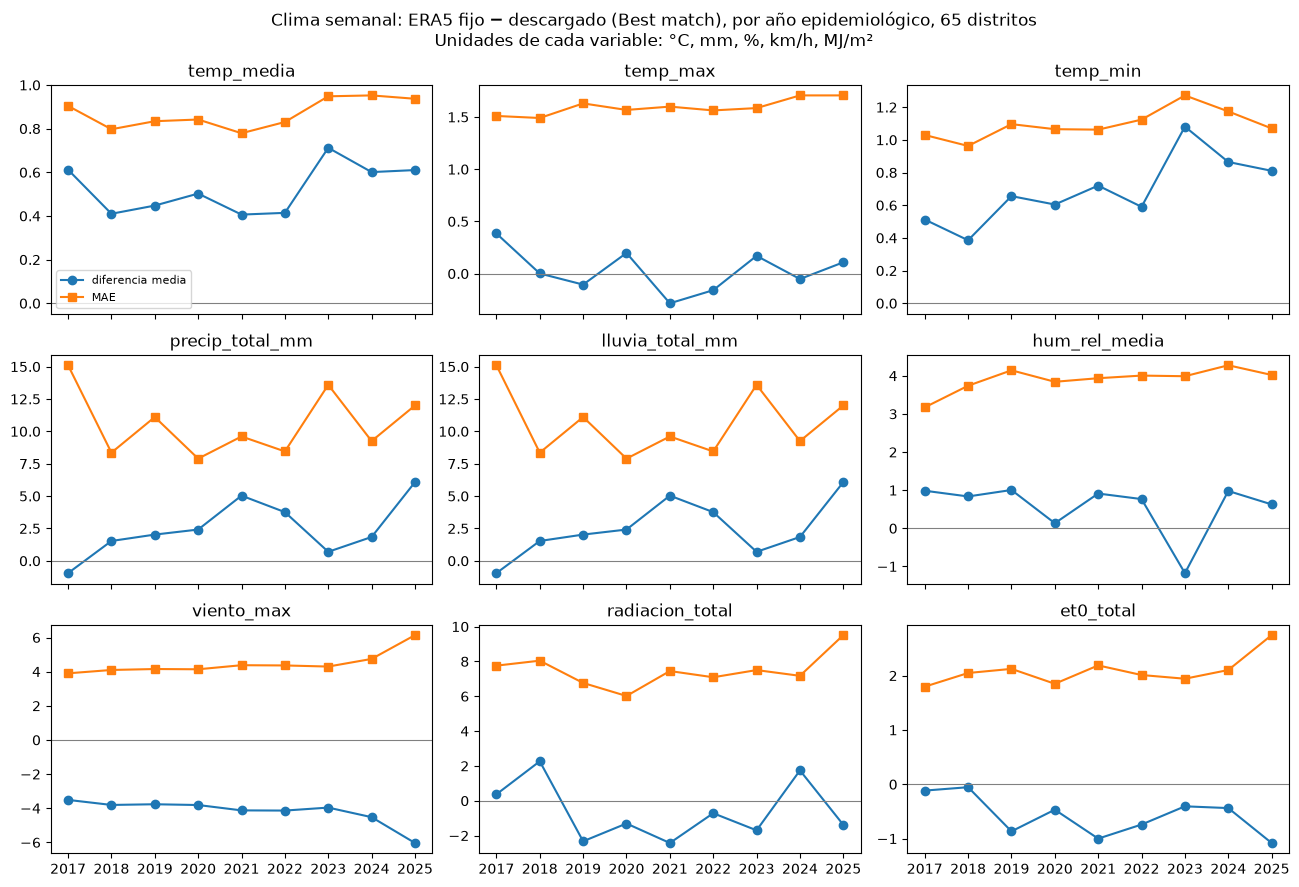

In [5]:
FIGURES.mkdir(parents=True, exist_ok=True)
variables = cl.WEEKLY_VARIABLES
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, v in zip(axes.flat, variables):
    t = by_year[by_year.variable.eq(v)]
    ax.plot(t.anio, t.diferencia_media, marker="o", label="diferencia media")
    ax.plot(t.anio, t.mae, marker="s", label="MAE")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(v)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Clima semanal: ERA5 fijo − descargado (Best match), por año epidemiológico, 65 distritos\n"
             "Unidades de cada variable: °C, mm, %, km/h, MJ/m²")
fig.tight_layout()
fig.savefig(FIGURES / "diferencia_era5_por_anio.png", dpi=130)


## 4 · Distritos que comparten celda o clima idéntico

ERA5 tiene una grilla de 0,25° (unos 28 km en Piura); varios distritos pequeños pueden caer en la misma celda.

- **Celda teórica:** el punto de la grilla de 0,25° más cercano al centroide de cada distrito. Es una
  aproximación: Open-Meteo puede elegir una celda vecina con tierra y elevación parecida.
- **Celda real de ERA5:** la que devolvió el API (`lat_celda`, `lon_celda`; la descarga con modelo fijo la guarda).
- **Clima idéntico:** grupos de distritos cuya serie semanal entera (9 variables, todas las semanas) es igual,
  en lo descargado hoy y en ERA5. Lo descargado hoy no guardó su celda, así que ahí solo se mira la serie.


In [6]:
districts = pd.read_csv(cl.DISTRICT_COORDS)
cells = {"teorica_0_25": cl.shared_cells(cl.nearest_era5_cell(districts)),
         "real_era5": cl.shared_cells(cl.cells_from_cache(CACHE_METEO_ERA5_2017_2025))}
pares = res["pares"]
current = pares[cl.KEY + [f"{v}_actual" for v in cl.WEEKLY_VARIABLES]].rename(columns=lambda c: c.removesuffix("_actual"))
fixed = pares[cl.KEY + [f"{v}_fijo" for v in cl.WEEKLY_VARIABLES]].rename(columns=lambda c: c.removesuffix("_fijo"))
identical = {"descargado_hoy": cl.identical_series(current), "era5": cl.identical_series(fixed)}
display(pd.DataFrame({k: {m: v[m] for m in ("distritos", "celdas", "distritos_que_comparten")} for k, v in cells.items()}))
display(pd.DataFrame({k: {m: v[m] for m in ("distritos", "series_distintas", "distritos_con_serie_identica")}
                      for k, v in identical.items()}))
{"grupos_celda_real": cells["real_era5"]["grupos"], "grupos_identicos_hoy": identical["descargado_hoy"]["grupos"],
 "grupos_identicos_era5": identical["era5"]["grupos"]}


,teorica_0_25,real_era5
distritos,65,65
celdas,35,34
distritos_que_comparten,47,48


,descargado_hoy,era5
distritos,65,65
series_distintas,65,65
distritos_con_serie_identica,0,0


{'grupos_celda_real': [[45.0, 46.0, 47.0, 48.0, 50.0],
  [16.0, 18.0],
  [40.0, 41.0, 65.0],
  [36.0, 38.0],
  [19.0, 22.0, 23.0, 25.0],
  [11.0, 15.0, 26.0, 28.0],
  [30.0, 31.0, 32.0],
  [43.0, 51.0, 55.0],
  [21.0, 44.0],
  [2.0, 27.0],
  [6.0, 20.0],
  [29.0, 34.0, 35.0, 52.0, 60.0],
  [56.0, 58.0],
  [7.0, 8.0],
  [4.0, 5.0],
  [3.0, 9.0],
  [59.0, 62.0, 63.0]],
 'grupos_identicos_hoy': [],
 'grupos_identicos_era5': []}

### Por variable dentro de cada celda real de ERA5

Que ninguna serie entera sea idéntica no descarta que algunas variables sí lo sean. Para cada grupo de distritos
con la misma celda real se mide la fracción de semanas con el mismo valor semanal en todos los distritos del grupo,
por variable, en ERA5 y en lo descargado hoy (con los mismos grupos).


In [7]:
def same_within_groups(weekly, groups):
    rows = []
    for g in groups:
        sub = weekly[weekly.id_distrito.isin(g)]
        for v in cl.WEEKLY_VARIABLES:
            same = sub.groupby("semana_inicio")[v].nunique().eq(1).mean()
            rows.append({"grupo": "-".join(str(int(i)) for i in g), "distritos": len(g), "variable": v, "iguales": same})
    return pd.DataFrame(rows)

groups = cells["real_era5"]["grupos"]
within = pd.concat({k: same_within_groups(w, groups) for k, w in (("era5", fixed), ("descargado_hoy", current))},
                   names=["fuente"]).reset_index(level=0)
within.pivot_table(index="variable", columns="fuente", values="iguales", aggfunc="median").round(3)


fuente,descargado_hoy,era5
variable,,
et0_total,0.000,0.000
hum_rel_media,0.002,0.525
lluvia_total_mm,0.222,1.000
precip_total_mm,0.222,1.000
radiacion_total,0.000,1.000
temp_max,0.000,0.000
temp_media,0.000,0.000
temp_min,0.002,0.000
viento_max,0.006,1.000


## 5 · Cifras guardadas


In [8]:
content = {
    "cobertura": res["cobertura"],
    "modelo_fijo_cache": CACHE_METEO_ERA5_2017_2025.name,
    "por_variable": res["por_variable"].to_dict(orient="records"),
    "por_variable_anio": by_year.to_dict(orient="records"),
    "celdas_compartidas": cells,
    "series_identicas": identical,
    "iguales_dentro_de_celda": within.to_dict(orient="records"),
}
content = json.loads(json.dumps(content, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
METRICS.write_text(json.dumps(content, ensure_ascii=False, indent=1), encoding="utf-8")
METRICS


WindowsPath('C:/Users/Rosa/RufoEsEternoElRegreso/Denguekay/research/06_model_improvement/docs/metricas/fase1b_consistencia.json')